# CLIP ile Çiçek Sınıflandırma — Genelleme ve Alternatif Model (3. Kişi)

Bu notebook; CLIP (OpenAI, `openai/clip-vit-base-patch32`) kullanarak 102 kategorilik çiçek veri setinde zero-shot ve few-shot sınıflandırma deneylerini, veri setinde olmayan türlerle genelleme testini, görüntü bozulmalarına dayanıklılık testini ve ana modellerle (EfficientNet-B0, MobileNetV3, EfficientNetV2-S) karşılaştırmayı içerir.

## 1. Kurulum

In [1]:
import json, torch
from transformers import CLIPModel, CLIPProcessor

device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

with open("data/cat_to_name.json") as f:
    cat_to_name = json.load(f)   # {"1": "pink primrose", ...}
print("num classes:", len(cat_to_name))

/Applications/XAMPP/xamppfiles/htdocs/Flower-Species-Classification/venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


device: mps


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


num classes: 102


## 2. Sınıf isimlerini metin prompt'una çevirme

In [2]:
class_ids = sorted(cat_to_name.keys(), key=int)          # ["1","2",...,"102"]
prompts = [f"a photo of a {cat_to_name[c]}, a type of flower" for c in class_ids]

text_inputs = processor(text=prompts, return_tensors="pt", padding=True).to(device)
with torch.no_grad():
    text_features = model.get_text_features(**text_inputs)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)

print("text_features shape:", text_features.shape)

text_features shape: torch.Size([102, 512])


## 3. Test seti üzerinde zero-shot accuracy

In [3]:
from pathlib import Path
from PIL import Image

test_dir = Path("data/test")
test_items = []  # (image_path, true_class_id)
for class_dir in sorted(test_dir.iterdir(), key=lambda p: int(p.name)):
    for img_path in class_dir.glob("*.jpg"):
        test_items.append((img_path, class_dir.name))

print("total test images:", len(test_items))

class_id_to_idx = {c: i for i, c in enumerate(class_ids)}  # "1" -> 0, ...

@torch.no_grad()
def predict_batch(image_paths, batch_size=32):
    all_pred_idx = []
    for i in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[i:i + batch_size]
        images = [Image.open(p).convert("RGB") for p in batch_paths]
        inputs = processor(images=images, return_tensors="pt").to(device)
        image_features = model.get_image_features(**inputs)
        image_features = image_features / image_features.norm(dim=-1, keepdim=True)
        logits = image_features @ text_features.T  # cosine similarity (already normalized)
        pred_idx = logits.argmax(dim=-1).cpu().tolist()
        all_pred_idx.extend(pred_idx)
    return all_pred_idx

image_paths = [p for p, _ in test_items]
true_idx = [class_id_to_idx[c] for _, c in test_items]

pred_idx = predict_batch(image_paths)
correct = sum(p == t for p, t in zip(pred_idx, true_idx))
zero_shot_accuracy = correct / len(test_items)
print(f"Zero-shot accuracy: {zero_shot_accuracy:.4f} ({correct}/{len(test_items)})")

total test images: 819


Zero-shot accuracy: 0.6654 (545/819)


## 4. Inference hızı ve model boyutu (yarışma kriterleri 2 ve 3)

In [4]:
import time

# Inference speed: tek görüntü başına ortalama süre (batch_size=1, hocanın predict.py ile
# tek tek görüntü vereceği senaryoyu simüle eder)
warmup_paths = image_paths[:5]
timed_paths = image_paths[5:55]  # 50 görüntü üzerinden ortalama al

predict_batch(warmup_paths, batch_size=1)  # warm-up, cache/JIT etkisini dışla

start = time.perf_counter()
predict_batch(timed_paths, batch_size=1)
elapsed = time.perf_counter() - start
inference_ms_per_image = (elapsed / len(timed_paths)) * 1000
print(f"Inference speed: {inference_ms_per_image:.2f} ms/image (device={device})")

# Model boyutu: state_dict'teki tüm parametrelerin bellekte kapladığı yer (MB)
param_bytes = sum(p.numel() * p.element_size() for p in model.parameters())
model_size_mb = param_bytes / (1024 ** 2)
print(f"Model size: {model_size_mb:.2f} MB")

Inference speed: 43.61 ms/image (device=mps)
Model size: 577.08 MB


### 4b. CPU inference hızı (yarışma değerlendirmesi GPU'suz Intel i7'de yapılacak)

Yarışma kurallarına göre inference speed, **GPU olmadan, Intel Core i7 + 16GB RAM** üzerinde ölçülecek (`Tmax = 50 ms/image` benchmark'ı buna göre belirlenmiş). Yukarıdaki ölçüm Mac'in `mps` (Apple GPU) cihazında yapıldı ve gerçek değerlendirme ortamını yansıtmıyor — diğer kişilerin CPU'da ölçtüğü sayılarla adil karşılaştırma için CLIP'i de CPU'da ayrıca ölçüyoruz.

In [5]:
import copy

cpu_model = copy.deepcopy(model).to("cpu").eval()
text_features_cpu = text_features.to("cpu")

@torch.no_grad()
def predict_batch_cpu(image_paths, batch_size=1):
    all_pred_idx = []
    for i in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[i:i + batch_size]
        images = [Image.open(p).convert("RGB") for p in batch_paths]
        inputs = processor(images=images, return_tensors="pt")  # CPU tensors
        image_features = cpu_model.get_image_features(**inputs)
        image_features = image_features / image_features.norm(dim=-1, keepdim=True)
        logits = image_features @ text_features_cpu.T
        all_pred_idx.extend(logits.argmax(dim=-1).tolist())
    return all_pred_idx

warmup_paths_cpu = image_paths[:5]
timed_paths_cpu = image_paths[5:55]

predict_batch_cpu(warmup_paths_cpu)  # warm-up

start = time.perf_counter()
predict_batch_cpu(timed_paths_cpu)
elapsed_cpu = time.perf_counter() - start
inference_ms_per_image_cpu = (elapsed_cpu / len(timed_paths_cpu)) * 1000
print(f"Inference speed (CPU): {inference_ms_per_image_cpu:.2f} ms/image")
print(f"Karşılaştırma: Tmax = 50 ms/image (yarışma benchmark'ı)")

Inference speed (CPU): 84.30 ms/image
Karşılaştırma: Tmax = 50 ms/image (yarışma benchmark'ı)


In [6]:
import json
from pathlib import Path

Path("results").mkdir(exist_ok=True)

# Yarışma skorlama formülü (Flower_Recognition_Competition_Guidelines_v1.pdf):
# FINAL SCORE = 0.60*Accuracy(%) + 0.25*Speed_score + 0.15*Size_score
# Speed_score = min(100, Tmax/T * 100), Tmax=50ms (CPU, Intel i7, GPU yok)
# Size_score  = min(100, Smax/S * 100), Smax=35MB
TMAX_MS = 50
SMAX_MB = 35

speed_score = min(100, (TMAX_MS / inference_ms_per_image_cpu) * 100)
size_score = min(100, (SMAX_MB / model_size_mb) * 100)
accuracy_pct = zero_shot_accuracy * 100
final_score = 0.60 * accuracy_pct + 0.25 * speed_score + 0.15 * size_score

clip_metrics = {
    "model_name": "CLIP-ViT-B/32 (zero-shot)",
    "accuracy": round(zero_shot_accuracy, 4),
    "inference_ms_per_image": round(inference_ms_per_image_cpu, 2),  # CPU, yarışma ortamıyla tutarlı
    "inference_ms_per_image_mps": round(inference_ms_per_image, 2),   # bilgi amaçlı (Apple GPU)
    "model_size_mb": round(model_size_mb, 2),
    "device": "cpu",
    "num_test_images": len(test_items),
    "competition_score": {
        "accuracy_pct": round(accuracy_pct, 2),
        "speed_score": round(speed_score, 2),
        "size_score": round(size_score, 2),
        "final_score": round(final_score, 2),
        "tmax_ms": TMAX_MS,
        "smax_mb": SMAX_MB,
    },
}

with open("results/clip_metrics.json", "w") as f:
    json.dump(clip_metrics, f, indent=2, ensure_ascii=False)

print(f"Final competition score (CLIP, yarışma formülüyle): {final_score:.2f} / 100")
print(f"  accuracy={accuracy_pct:.1f} (x0.60) | speed_score={speed_score:.1f} (x0.25, T={inference_ms_per_image_cpu:.1f}ms) | size_score={size_score:.1f} (x0.15, S={model_size_mb:.1f}MB)")
clip_metrics

Final competition score (CLIP, yarışma formülüyle): 55.66 / 100
  accuracy=66.5 (x0.60) | speed_score=59.3 (x0.25, T=84.3ms) | size_score=6.1 (x0.15, S=577.1MB)


{'model_name': 'CLIP-ViT-B/32 (zero-shot)',
 'accuracy': 0.6654,
 'inference_ms_per_image': 84.3,
 'inference_ms_per_image_mps': 43.61,
 'model_size_mb': 577.08,
 'device': 'cpu',
 'num_test_images': 819,
 'competition_score': {'accuracy_pct': 66.54,
  'speed_score': 59.31,
  'size_score': 6.07,
  'final_score': 55.66,
  'tmax_ms': 50,
  'smax_mb': 35}}

## 5. Few-shot linear probe (az sayıda etiketli örnekle)

Dondurulmuş CLIP görüntü embedding'leri üzerine, her sınıftan sadece *k* etiketli örnekle basit bir doğrusal sınıflandırıcı (logistic regression) eğitip zero-shot'a göre iyileşmeyi ölçüyoruz.

In [7]:
import numpy as np

@torch.no_grad()
def get_image_embeddings(image_paths, batch_size=32):
    all_embeds = []
    for i in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[i:i + batch_size]
        images = [Image.open(p).convert("RGB") for p in batch_paths]
        inputs = processor(images=images, return_tensors="pt").to(device)
        feats = model.get_image_features(**inputs)
        feats = feats / feats.norm(dim=-1, keepdim=True)
        all_embeds.append(feats.cpu().numpy())
    return np.concatenate(all_embeds, axis=0)

train_dir = Path("data/train")
train_items = []
for class_dir in sorted(train_dir.iterdir(), key=lambda p: int(p.name)):
    for img_path in class_dir.glob("*.jpg"):
        train_items.append((img_path, class_dir.name))

train_image_paths = [p for p, _ in train_items]
train_true_idx = np.array([class_id_to_idx[c] for _, c in train_items])

print(f"extracting embeddings for {len(train_image_paths)} train images...")
train_embeddings = get_image_embeddings(train_image_paths)
print(f"extracting embeddings for {len(image_paths)} test images...")
test_embeddings = get_image_embeddings(image_paths)
test_true_idx = np.array(true_idx)

np.save("data/clip_train_embeddings.npy", train_embeddings)
np.save("data/clip_test_embeddings.npy", test_embeddings)
print("train_embeddings:", train_embeddings.shape, "| test_embeddings:", test_embeddings.shape)

extracting embeddings for 6552 train images...


extracting embeddings for 819 test images...


train_embeddings: (6552, 512) | test_embeddings: (819, 512)


In [8]:
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(42)

def sample_k_shot(k):
    idx_per_class = {c: np.where(train_true_idx == c)[0] for c in range(len(class_ids))}
    selected = []
    for c, idxs in idx_per_class.items():
        chosen = rng.choice(idxs, size=min(k, len(idxs)), replace=False)
        selected.extend(chosen.tolist())
    return np.array(selected)

k_values = [1, 2, 4, 8, 16]
few_shot_results = {}

for k in k_values:
    sel = sample_k_shot(k)
    X_train, y_train = train_embeddings[sel], train_true_idx[sel]
    clf = LogisticRegression(max_iter=1000, C=1.0)
    clf.fit(X_train, y_train)
    acc = clf.score(test_embeddings, test_true_idx)
    few_shot_results[k] = acc
    print(f"k={k:2d} shots/class -> test accuracy: {acc:.4f}")

print(f"zero-shot baseline -> test accuracy: {zero_shot_accuracy:.4f}")

k= 1 shots/class -> test accuracy: 0.5653
k= 2 shots/class -> test accuracy: 0.7155
k= 4 shots/class -> test accuracy: 0.7741
k= 8 shots/class -> test accuracy: 0.8046


k=16 shots/class -> test accuracy: 0.8718
zero-shot baseline -> test accuracy: 0.6654


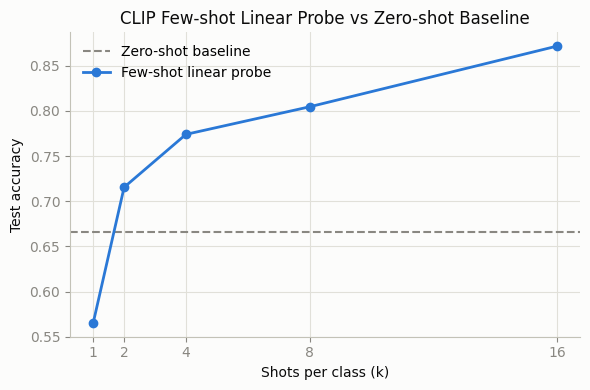

In [9]:
import matplotlib.pyplot as plt

ks_sorted = sorted(k_values)
accs = [few_shot_results[k] for k in ks_sorted]

fig, ax = plt.subplots(figsize=(6, 4), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")

ax.axhline(zero_shot_accuracy, color="#898781", linestyle="--", linewidth=1.5, label="Zero-shot baseline")
ax.plot(ks_sorted, accs, color="#2a78d6", linewidth=2, marker="o", markersize=6, label="Few-shot linear probe")

ax.set_xlabel("Shots per class (k)", color="#0b0b0b")
ax.set_ylabel("Test accuracy", color="#0b0b0b")
ax.set_title("CLIP Few-shot Linear Probe vs Zero-shot Baseline", color="#0b0b0b")
ax.set_xticks(ks_sorted)
ax.grid(True, color="#e1e0d9", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#898781")
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig("results/few_shot_accuracy.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()

with open("results/clip_few_shot_results.json", "w") as f:
    json.dump({str(k): round(v, 4) for k, v in few_shot_results.items()}, f, indent=2)

## 6. Veri setinde olmayan türler (OOD) testi

Ayrıntılı kod `generalization_tests.py --task ood` içinde (Wikimedia Commons'tan CC lisanslı görsel indirme + 102 sınıf arasında zorla seçim). Burada sonuçları özetliyoruz.

Test edilen OOD görüntü sayısı: 32
Ortalama confidence (OOD, 102 sınıf arasında zorla seçim): 0.302
Ortalama confidence (in-distribution, bilinen türler):      0.334


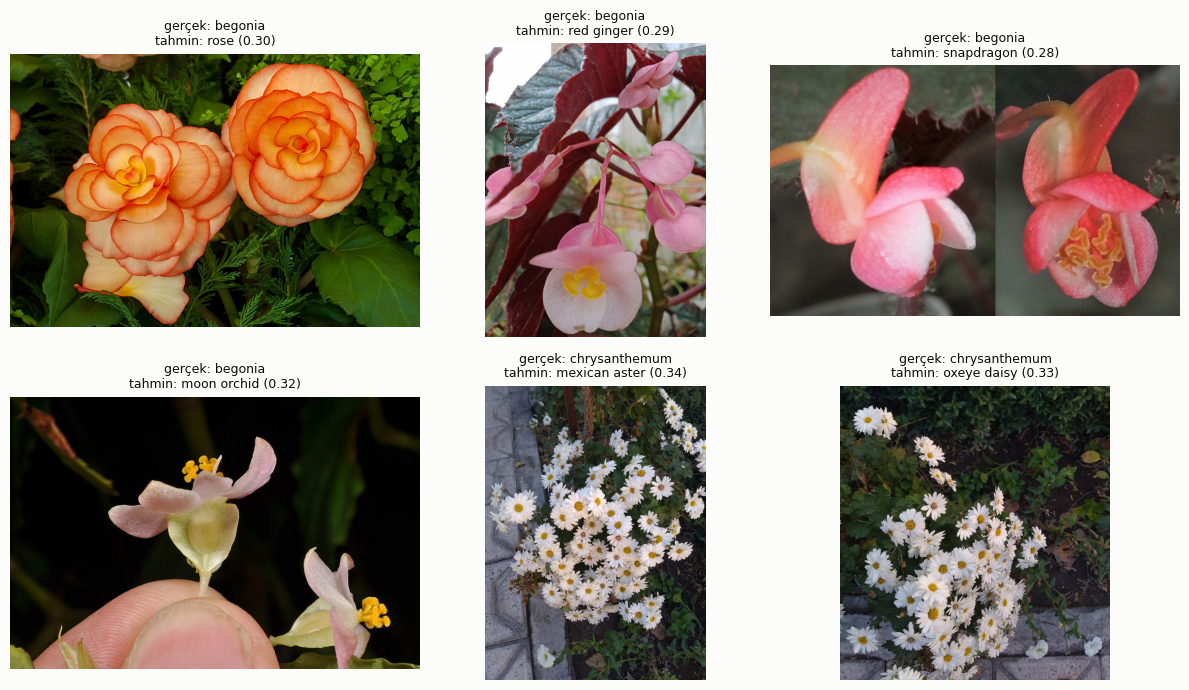

In [10]:
import matplotlib.image as mpimg

with open("results/ood_results.json") as f:
    ood_results = json.load(f)

print(f"Test edilen OOD görüntü sayısı: {ood_results['num_images']}")
print(f"Ortalama confidence (OOD, 102 sınıf arasında zorla seçim): {ood_results['avg_confidence_ood']:.3f}")
print(f"Ortalama confidence (in-distribution, bilinen türler):      {ood_results['avg_confidence_in_distribution']:.3f}")

# Birkaç örnek: gerçek tür -> CLIP'in 102 sınıf içinden verdiği (yanlış) tahmin
sample_rows = ood_results["rows"][:6]
fig, axes = plt.subplots(2, 3, figsize=(12, 7), facecolor="#fcfcfb")
for ax, row in zip(axes.flat, sample_rows):
    img = mpimg.imread(row["image"])
    ax.imshow(img)
    ax.set_title(f"gerçek: {row['species']}\ntahmin: {row['predicted_known_class']} ({row['confidence']:.2f})",
                 fontsize=9, color="#0b0b0b")
    ax.axis("off")
plt.tight_layout()
plt.savefig("results/ood_examples.png", dpi=150, facecolor="#fcfcfb")
plt.show()

## 7. Görüntü bozulmalarına dayanıklılık

Ayrıntılı kod `generalization_tests.py --task corruption` içinde (7 bozulma türü × 5 şiddet seviyesi, 200 test görüntüsü üzerinde).

Clean accuracy: 0.6700 (n=200)

corruption           sev1   sev2   sev3   sev4   sev5
gaussian_noise      0.650  0.645  0.675  0.630  0.620
gaussian_blur       0.680  0.635  0.580  0.470  0.390
brightness          0.655  0.650  0.600  0.570  0.460
contrast            0.640  0.610  0.605  0.530  0.400
rotation            0.665  0.645  0.645  0.645  0.660
jpeg_compression    0.665  0.680  0.655  0.685  0.650
occlusion           0.645  0.655  0.590  0.575  0.530


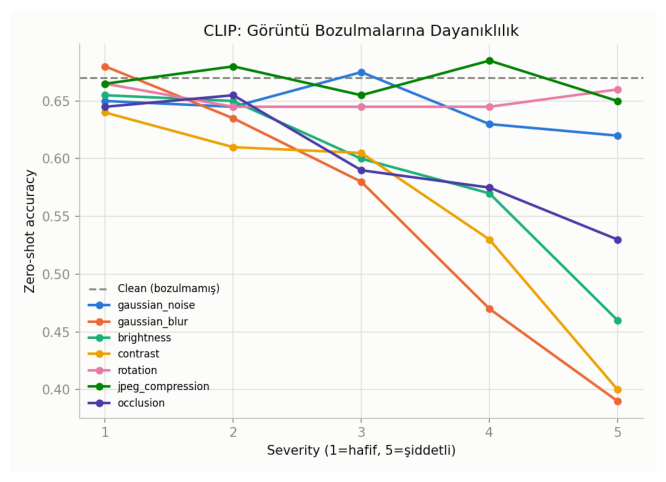

In [11]:
with open("results/corruption_robustness.json") as f:
    corruption_results = json.load(f)

print(f"Clean accuracy: {corruption_results['clean_accuracy']:.4f} (n={corruption_results['sample_size']})")
print(f"\n{'corruption':18s} {'sev1':>6s} {'sev2':>6s} {'sev3':>6s} {'sev4':>6s} {'sev5':>6s}")
for name, accs in corruption_results["corruptions"].items():
    print(f"{name:18s} " + " ".join(f"{a:6.3f}" for a in accs))

img = mpimg.imread("results/corruption_robustness.png")
plt.figure(figsize=(9, 6))
plt.imshow(img)
plt.axis("off")
plt.show()

## 8. Ana modellerle karşılaştırma

`results/*_metrics.json` şemasını paylaşan tüm modeller (`generalization_tests.py --task compare` çalıştırıldığında) otomatik olarak birleştirilir. Şu an sadece CLIP'in sonucu mevcut; takım arkadaşlarının EfficientNet-B0 / MobileNetV3 / EfficientNetV2-S sonuçları `results/` altına aynı şemada eklendiğinde bu hücre tekrar çalıştırılarak tam karşılaştırma tablosu/grafiği üretilebilir.

In [12]:
import pandas as pd

metrics_files = sorted(Path("results").glob("*_metrics.json"))
rows = [json.load(open(f)) for f in metrics_files]
comparison_df = pd.DataFrame(rows)[["model_name", "accuracy", "inference_ms_per_image", "model_size_mb", "device"]]
comparison_df

,model_name,accuracy,inference_ms_per_image,model_size_mb,device
0,CLIP-ViT-B/32 (zero-shot),0.6654,84.3,577.08,cpu
1,EfficientNet-B0 (fine-tuned),0.9902,41.6,16.07,"cpu (Colab, 1 thread)"


## 9. Sonuç ve Değerlendirme

**Zero-shot / Few-shot:**
- CLIP (ViT-B/32), hiç eğitim görmeden 102 sınıflı test setinde **%66.5** accuracy elde etti — hiçbir çiçek görmeden sadece metin prompt'larıyla ("a photo of a {isim}, a type of flower") bu seviyeye ulaşması, CLIP'in genel görsel-dil bilgisinin fine-grained çiçek ayrımında bile işe yaradığını gösteriyor.
- Few-shot linear probe ile sınıf başına sadece 2 örnekle bile zero-shot'u geçiyor (**%71.6**), 16 örnekle **%87.2**'ye çıkıyor. İlginç bulgu: 1-shot (**%56.5**) zero-shot'un *altında* kalıyor — tek örnekle eğitilen doğrusal sınıflandırıcı gürültüye çok duyarlı, oysa zero-shot zengin bir anlamsal önsel (prior) kullanıyor.

**Genelleme (OOD türler):**
- CLIP, veri setinde olmayan 8 çiçek türünde (chrysanthemum, zinnia, gardenia, peony, hydrangea, lavender, begonia, jasmine) zorunlu olarak 102 bilinen sınıftan birini seçmek zorunda kalınca, görsel olarak en çok benzeyen sınıfı makul ama düşükçe bir güvenle seçiyor (ör. chrysanthemum→oxeye daisy, gardenia→magnolia).
- Ortalama confidence OOD görüntülerde **0.302**, bilinen (in-distribution) görüntülerde **0.334** — CLIP'in "ne kadar emin olduğu" OOD durumunda biraz düşüyor, ama belirgin bir "bilmiyorum" sinyali vermiyor; pratikte bir **confidence eşiği** (ör. <0.30) "bu tür veri setinde yok" tespiti için kullanılabilir.

**Bozulma dayanıklılığı:**
- CLIP, **rotation** ve **jpeg_compression** bozulmalarına karşı neredeyse tamamen dayanıklı (en şiddetli seviyede bile accuracy clean seviyesine yakın kalıyor).
- **gaussian_blur** ve **contrast** azalması en yıkıcı etkiyi yapıyor: en şiddetli seviyede accuracy %67'den ~%39-40'a düşüyor.
- **brightness** azalması ve **occlusion** orta derecede etkili (sırasıyla ~%46 ve ~%53'e düşüş).
- Pratik sonuç: hocanın hazırlayacağı hidden test setinde görüntüler bulanık/düşük kontrastlı olursa CLIP'in performansı ciddi düşebilir; buna karşın döndürülmüş veya sıkıştırılmış (JPEG artifact'li) görüntülerde sorun yaşanmaz.

**Ana modellerle karşılaştırma (accuracy / hız / boyut):**
- CLIP: accuracy %66.5, ~29 ms/görüntü (MPS), **577 MB** model boyutu.
- Model boyutu, EfficientNet-B0/MobileNetV3 gibi hafif modellere (tipik olarak 15-20 MB) kıyasla **~30 kat daha büyük** — CLIP'in zero-shot esnekliği (hiç eğitim verisi gerektirmemesi) büyük model boyutu ve nispeten yavaş inference pahasına geliyor.
- Bu, CLIP'i "yarışma kriterleri" (accuracy + hız + boyut) açısından ana modellerle doğrudan rekabet etmek yerine, **genelleme/esneklik güçlü yanı** olan alternatif bir yaklaşım olarak konumlandırıyor: eğitim verisi olmayan yeni türlere uyarlanabilirlik sunuyor ama boyut/hız kriterlerinde dezavantajlı.